In [95]:
from datasets import load_dataset
import pandas as pd
from hazm import Normalizer
import re
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
from sklearn.utils import compute_class_weight
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import os
import joblib

In [2]:
dataset_path = 'HooshvareLab/pn_summary'

train_ds = load_dataset(dataset_path, split='train')
test_ds = load_dataset(dataset_path, split='test')
val_ds = load_dataset(dataset_path, split='validation')

train_ds, test_ds, val_ds

(Dataset({
     features: ['id', 'title', 'article', 'summary', 'category', 'categories', 'network', 'link'],
     num_rows: 82022
 }),
 Dataset({
     features: ['id', 'title', 'article', 'summary', 'category', 'categories', 'network', 'link'],
     num_rows: 5593
 }),
 Dataset({
     features: ['id', 'title', 'article', 'summary', 'category', 'categories', 'network', 'link'],
     num_rows: 5592
 }))

In [12]:
def ds_to_df(ds):
    return pd.DataFrame({'summary': ds['summary'], 'category': ds['category']})

In [13]:
train_df = ds_to_df(train_ds)
test_df = ds_to_df(test_ds)
val_df = ds_to_df(val_ds)

In [14]:
train_df

,summary,category
0,مدیرعامل شرکت ملی نفت، عملکرد مدیریت امور بین‎...,5
1,سرپرست مدیریت برنامه‌ریزی و توسعه شرکت ملی صنا...,5
2,پالایشگاه گاز خانگیران با هدف معرفی گوگرد بنتو...,5
3,سخنگوی شورای شهر شیراز گفت: روند عمرانی و شهرس...,9
4,مشاور وزیر نفت و مدیرکل اچ اس یی و پدافند غیرع...,5
...,...,...
82017,تیم‌های ملی هاکی زنان و مردان ایران در سومین د...,10
82018,قلی خسروی، رئیس اتحادیه مشاوران املاک تهران گف...,1
82019,رئیس کمیته امداد از آغاز مرحله دوم پویش ایران ...,13
82020,گروه صنعتی ایران‌خودرو به منظور تامین نیاز مشت...,0


In [15]:
test_df

,summary,category
0,مصرف نفت کوره منطقه سبزوار در بهار امسال، نسبت...,5
1,رویدادی در آزمایشگاه نقشه برداری مغز در راستای...,8
2,دبیرکل سازمان کشورهای صادرکننده نفت (اوپک) اعل...,4
3,سخنگوی سازمان آتش نشانی اصفهان از حریق در کارگ...,13
4,بی بی س خبر داد: با ادامه شمارش آرا، پیشتازی ت...,4
...,...,...
5588,سخنگوی گمرک گفت: میزان تجارت خارجی ایران در چه...,0
5589,شرکت هندوستان پترولیوم فرایند پرداخت بدهی نفتی...,4
5590,جمعی از نمایندگان مجلس شورای اسلامی تاکید کردن...,9
5591,یافته‌های جدید محققان نشان می‌دهد ورزش‌کردن، ن...,8


In [16]:
val_df

,summary,category
0,شانا گروه پالایش و پخش: کارمزد چهار فرآورده نف...,5
1,هواپیماهای ارتش ترکیه برای انتقال تیم‌های امدا...,11
2,بهره برداری از خط ششم سراسری علاوه بر آنکه نقش...,5
3,این جزیره که زمانی زندانی برای نگهداری از خطرن...,17
4,وزیر راه و شهرسازی ضمن عرض تسلیت از جان باختن ...,0
...,...,...
5587,عضو کمیسیون انرژی مجلس شورای اسلامی با بیان ای...,5
5588,مصرف بنزین ۷ ماه امسال منطقه تهران با افزایش ب...,5
5589,شانا گروه گاز: مرگ و میر ناشی از مرگ خاموش (گا...,5
5590,بیرجند-رئیس اداره منابع طبیعی و آبخیزداری شهرس...,9


In [17]:
train_df['category'].value_counts()

category
5     15856
9     13871
0      8939
4      8796
13     7773
10     6049
8      5770
11     4080
12     2894
6      1832
14     1378
1      1236
16     1060
2       731
15      712
7       521
3       364
17      160
Name: count, dtype: int64

In [19]:
category_map = {
    0: 'Economy',
    1: 'Roads-Urban',
    2: 'Banking-Insurance',
    3: 'Agriculture',
    4: 'International',
    5: 'Oil-Energy',
    6: 'Industry',
    7: 'Transportation',
    8: 'Science-Technology',
    9: 'Local',
    10: 'Sports',
    11: 'Politics',
    12: 'Art-Culture',
    13: 'Society',
    14: 'Health',
    15: 'Research',
    16: 'Education-University',
    17: 'Tourism'
}

In [20]:
train_df['category_name'] = train_df['category'].map(category_map)
test_df['category_name'] = test_df['category'].map(category_map)
val_df['category_name'] = val_df['category'].map(category_map)

In [21]:
train_df

,summary,category,category_name
0,مدیرعامل شرکت ملی نفت، عملکرد مدیریت امور بین‎...,5,Oil-Energy
1,سرپرست مدیریت برنامه‌ریزی و توسعه شرکت ملی صنا...,5,Oil-Energy
2,پالایشگاه گاز خانگیران با هدف معرفی گوگرد بنتو...,5,Oil-Energy
3,سخنگوی شورای شهر شیراز گفت: روند عمرانی و شهرس...,9,Local
4,مشاور وزیر نفت و مدیرکل اچ اس یی و پدافند غیرع...,5,Oil-Energy
...,...,...,...
82017,تیم‌های ملی هاکی زنان و مردان ایران در سومین د...,10,Sports
82018,قلی خسروی، رئیس اتحادیه مشاوران املاک تهران گف...,1,Roads-Urban
82019,رئیس کمیته امداد از آغاز مرحله دوم پویش ایران ...,13,Society
82020,گروه صنعتی ایران‌خودرو به منظور تامین نیاز مشت...,0,Economy


In [22]:
test_df

,summary,category,category_name
0,مصرف نفت کوره منطقه سبزوار در بهار امسال، نسبت...,5,Oil-Energy
1,رویدادی در آزمایشگاه نقشه برداری مغز در راستای...,8,Science-Technology
2,دبیرکل سازمان کشورهای صادرکننده نفت (اوپک) اعل...,4,International
3,سخنگوی سازمان آتش نشانی اصفهان از حریق در کارگ...,13,Society
4,بی بی س خبر داد: با ادامه شمارش آرا، پیشتازی ت...,4,International
...,...,...,...
5588,سخنگوی گمرک گفت: میزان تجارت خارجی ایران در چه...,0,Economy
5589,شرکت هندوستان پترولیوم فرایند پرداخت بدهی نفتی...,4,International
5590,جمعی از نمایندگان مجلس شورای اسلامی تاکید کردن...,9,Local
5591,یافته‌های جدید محققان نشان می‌دهد ورزش‌کردن، ن...,8,Science-Technology


In [23]:
val_df

,summary,category,category_name
0,شانا گروه پالایش و پخش: کارمزد چهار فرآورده نف...,5,Oil-Energy
1,هواپیماهای ارتش ترکیه برای انتقال تیم‌های امدا...,11,Politics
2,بهره برداری از خط ششم سراسری علاوه بر آنکه نقش...,5,Oil-Energy
3,این جزیره که زمانی زندانی برای نگهداری از خطرن...,17,Tourism
4,وزیر راه و شهرسازی ضمن عرض تسلیت از جان باختن ...,0,Economy
...,...,...,...
5587,عضو کمیسیون انرژی مجلس شورای اسلامی با بیان ای...,5,Oil-Energy
5588,مصرف بنزین ۷ ماه امسال منطقه تهران با افزایش ب...,5,Oil-Energy
5589,شانا گروه گاز: مرگ و میر ناشی از مرگ خاموش (گا...,5,Oil-Energy
5590,بیرجند-رئیس اداره منابع طبیعی و آبخیزداری شهرس...,9,Local


In [25]:
train_df.shape, test_df.shape, val_df.shape

((82022, 3), (5593, 3), (5592, 3))

In [27]:
train_df = train_df.dropna(subset=['summary', 'category', 'category_name'])
test_df = test_df.dropna(subset=['summary', 'category', 'category_name'])
val_df = val_df.dropna(subset=['summary', 'category', 'category_name'])
train_df.shape, test_df.shape, val_df.shape

((82022, 3), (5593, 3), (5592, 3))

In [28]:
normalizer = Normalizer()

def text_cleaning(text):
    if not isinstance(text, str):
        return ''

    text = normalizer.normalize(text)
    text = re.sub(r'\s+', ' ', text)

    return text

In [29]:
tqdm.pandas()

train_df['clean_summary'] = train_df['summary'].progress_apply(text_cleaning)
test_df['clean_summary'] = test_df['summary'].progress_apply(text_cleaning)
val_df['clean_summary'] = val_df['summary'].progress_apply(text_cleaning)

100%|██████████| 5592/5592 [00:05<00:00, 972.62it/s] 


In [30]:
train_df[['summary', 'clean_summary']]

,summary,clean_summary
0,مدیرعامل شرکت ملی نفت، عملکرد مدیریت امور بین‎...,مدیرعامل شرکت ملی نفت، عملکرد مدیریت امور بین‎...
1,سرپرست مدیریت برنامه‌ریزی و توسعه شرکت ملی صنا...,سرپرست مدیریت برنامه‌ریزی و توسعه شرکت ملی صنا...
2,پالایشگاه گاز خانگیران با هدف معرفی گوگرد بنتو...,پالایشگاه گاز خانگیران با هدف معرفی گوگرد بنتو...
3,سخنگوی شورای شهر شیراز گفت: روند عمرانی و شهرس...,سخنگوی شورای شهر شیراز گفت: روند عمرانی و شهرس...
4,مشاور وزیر نفت و مدیرکل اچ اس یی و پدافند غیرع...,مشاور وزیر نفت و مدیرکل اچ اس یی و پدافند غیرع...
...,...,...
82017,تیم‌های ملی هاکی زنان و مردان ایران در سومین د...,تیم‌های ملی هاکی زنان و مردان ایران در سومین د...
82018,قلی خسروی، رئیس اتحادیه مشاوران املاک تهران گف...,قلی‌خسروی، رئیس اتحادیه مشاوران املاک تهران گف...
82019,رئیس کمیته امداد از آغاز مرحله دوم پویش ایران ...,رئیس کمیته امداد از آغاز مرحله دوم پویش ایران ...
82020,گروه صنعتی ایران‌خودرو به منظور تامین نیاز مشت...,گروه صنعتی ایران‌خودرو به منظور تامین نیاز مشت...


In [31]:
le = LabelEncoder()

y_train = le.fit_transform(train_df['category_name'])
y_val   = le.transform(val_df['category_name'])
y_test  = le.transform(test_df['category_name'])

In [66]:
tfidf = TfidfVectorizer(
    max_features=12500,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True,
    encoding='utf-8'
)

In [67]:
x_train = tfidf.fit_transform(train_df['clean_summary'])
x_test = tfidf.transform(test_df['clean_summary'])
x_val = tfidf.transform(val_df['clean_summary'])

In [68]:
X_train = x_train.astype('float32').toarray()
X_test  = x_test.astype('float32').toarray()
X_val   = x_val.astype('float32').toarray()

In [69]:
classes = np.unique(y_train)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
class_weight_dict = dict(zip(classes, class_weights))

In [70]:
for cls, weight in class_weight_dict.items():
    print(f'{le.inverse_transform([cls])[0]:} → {weight:.3f}')

Agriculture → 12.519
Art-Culture → 1.575
Banking-Insurance → 6.234
Economy → 0.510
Education-University → 4.299
Health → 3.307
Industry → 2.487
International → 0.518
Local → 0.329
Oil-Energy → 0.287
Politics → 1.117
Research → 6.400
Roads-Urban → 3.687
Science-Technology → 0.790
Society → 0.586
Sports → 0.753
Tourism → 28.480
Transportation → 8.746


In [71]:
model = Sequential([
    Dense(256, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(len(classes), activation='softmax')
])

C:\Users\ASUS\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [72]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [73]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │     3,200,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,235,474 (12.34 MB)

 Trainable params: 3,235,474 (12.34 MB)

 Non-trainable params: 0 (0.00 B)

In [74]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

In [75]:
model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.6281 - loss: 1.4012 - val_accuracy: 0.7158 - val_loss: 0.9299
Epoch 2/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 25s 39ms/step - accuracy: 0.7547 - loss: 0.6400 - val_accuracy: 0.7251 - val_loss: 0.8593
Epoch 3/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.8036 - loss: 0.4168 - val_accuracy: 0.7402 - val_loss: 0.8205
Epoch 4/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.8413 - loss: 0.3041 - val_accuracy: 0.7507 - val_loss: 0.8103
Epoch 5/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.8706 - loss: 0.2303 - val_accuracy: 0.7527 - val_loss: 0.8576
Epoch 6/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 26s 40ms/step - accuracy: 0.8940 - loss: 0.1811 - val_accuracy: 0.7561 - val_loss: 0.9105
Epoch 7/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.9130 - loss: 0.1467 - val_accuracy: 0.7461 - val_loss: 0.9463
Epoch 8/30
641/641 ━━━━━━━━━━━━━━━━━━━━ 26s 40ms/step - accuracy: 0.9288 - loss: 0.1207 - 

In [76]:
y_pred_proba = model.predict(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')
acc, macro_f1, weighted_f1

175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


(0.7403897729304488, 0.6318434625897206, 0.7456329864628238)

In [77]:
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

                      precision    recall  f1-score   support

         Agriculture     0.4390    0.7200    0.5455        25
         Art-Culture     0.6960    0.8020    0.7453       197
   Banking-Insurance     0.4588    0.7800    0.5778        50
             Economy     0.6458    0.5599    0.5998       609
Education-University     0.1953    0.3472    0.2500        72
              Health     0.5333    0.8511    0.6557        94
            Industry     0.5686    0.6960    0.6259       125
       International     0.7329    0.7671    0.7496       601
               Local     0.8418    0.7191    0.7756       947
          Oil-Energy     0.8915    0.8289    0.8591      1081
            Politics     0.6125    0.6390    0.6254       277
            Research     0.5882    0.6250    0.6061        48
         Roads-Urban     0.5575    0.7500    0.6396        84
  Science-Technology     0.7281    0.7817    0.7540       394
             Society     0.7602    0.6987    0.7282       531
       

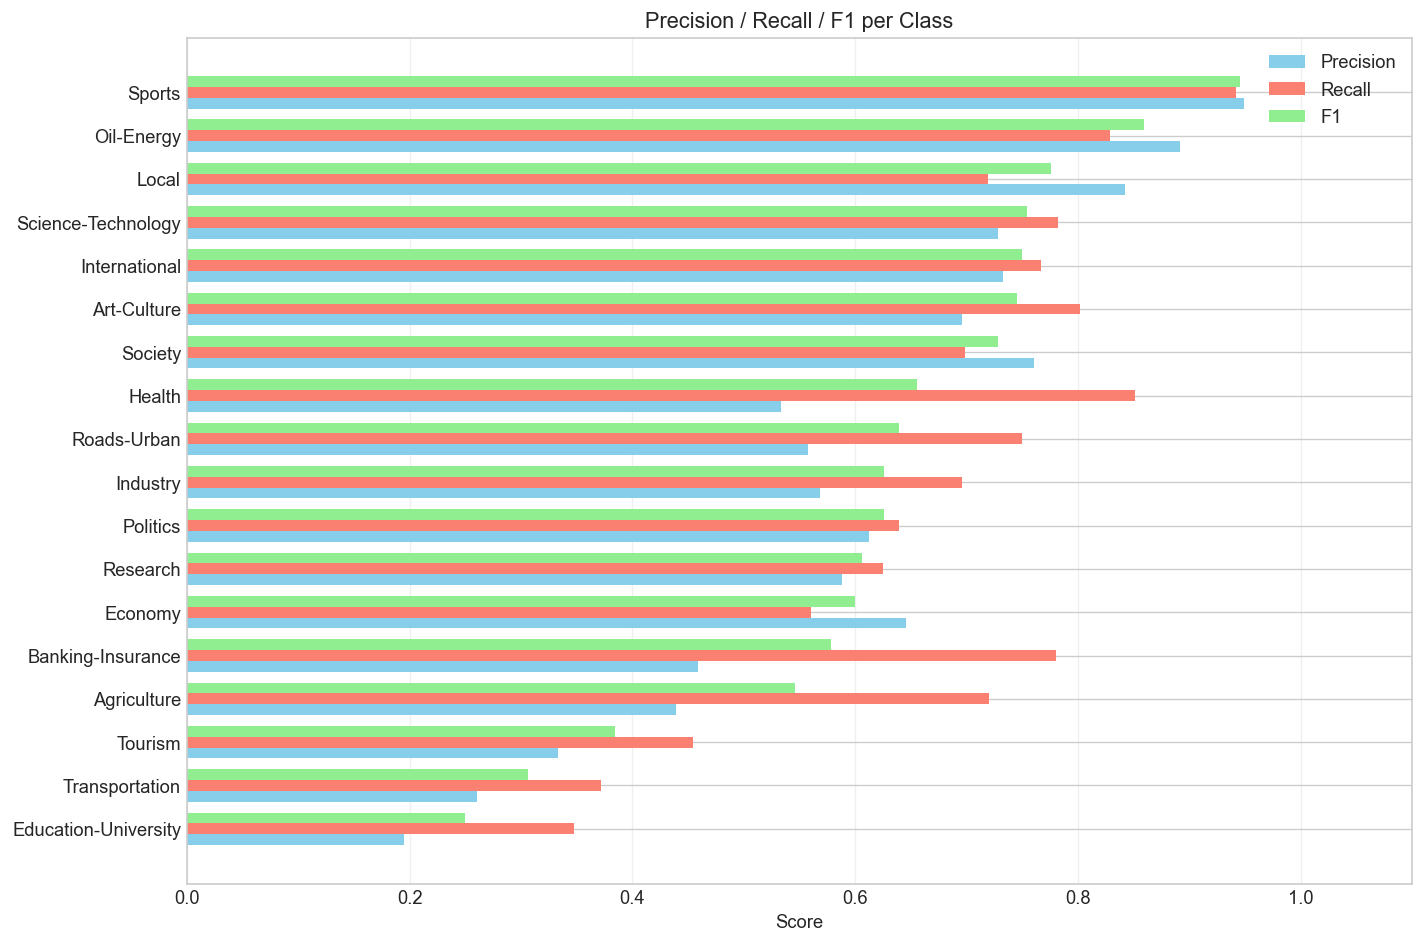

In [96]:
precision = precision_score(y_test, y_pred, average=None, zero_division=0)
recall    = recall_score(y_test, y_pred, average=None, zero_division=0)
f1        = f1_score(y_test, y_pred, average=None, zero_division=0)

metrics_df = pd.DataFrame({
    'Category': le.classes_,
    'Precision': precision,
    'Recall': recall,
    'F1': f1
}).sort_values('F1', ascending=True)

x = np.arange(len(metrics_df))
width = 0.25

plt.figure(figsize=(12, 8))
plt.barh(x - width, metrics_df['Precision'], width, label='Precision', color='skyblue')
plt.barh(x,         metrics_df['Recall'],    width, label='Recall',    color='salmon')
plt.barh(x + width, metrics_df['F1'],        width, label='F1',        color='lightgreen')

plt.yticks(x, metrics_df['Category'])
plt.xlabel('Score')
plt.title('Precision / Recall / F1 per Class')
plt.xlim(0, 1.1)
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [97]:
os.makedirs('model', exist_ok=True)
model.save('model/persian_news_classifier.keras')
joblib.dump(tfidf, 'model/tfidf_vectorizer.joblib')
joblib.dump(le, 'model/label_encoder.joblib')

['model/label_encoder.joblib']

In [98]:
def load_news_classifier(model_dir="model"):
    model = load_model(f"{model_dir}/persian_news_classifier.keras")
    tfidf = joblib.load(f"{model_dir}/tfidf_vectorizer.joblib")
    le = joblib.load(f"{model_dir}/label_encoder.joblib")
    return model, tfidf, le

In [99]:
def predict_news_category(text, model=None, tfidf=None, le=None, model_dir="model"):

    if model is None or tfidf is None or le is None:
        model, tfidf, le = load_news_classifier(model_dir)

    cleaned = text_cleaning(text)

    vector = tfidf.transform([cleaned]).astype('float32').toarray()

    proba = model.predict(vector, verbose=0)[0]
    pred_idx = np.argmax(proba)
    confidence = float(proba[pred_idx])
    category = le.inverse_transform([pred_idx])[0]

    return category, confidence

In [100]:
model, tfidf, le = load_news_classifier()
category, conf = predict_news_category('در داربی شماره 89 پایتخت میان تیم های استقلال و پرسپولیس تهران که به تساوی بدون گل انجامید کاپیتان مهدی مهدوی کیا کفش های خود را آویخت', model, tfidf, le)
category, conf

('Sports', 0.9396936893463135)